# 16 · Exhaustive rule scan

`15_simulation` showed the 29-term formula (`SPEC4`) is right but incomplete: CatBoost finds real structure it lacks. This notebook searches for the missing rules **exhaustively**, with a pure-chance threshold so the search can't invent rules.

**Candidates** (`rule_scan.py`, ~518 numeric and 17 categorical columns), each in every era scope (all, 2015-16, 2017-18, 2015, 2016):
- **every band** a ≤ x ≤ b, one-sided step and missing flag on every numeric column (up to 40 cut points), including driver- and vehicle-level rule counts and shares (e.g. share of drivers with accident-free years ≥ 5) and first-driver / first-vehicle values;
- **every subset** of the levels of each categorical (carrier, state, package, channel, parking, …);
- **every two-way step × step / step × level rule** over 49 base columns (scopes all / 2015-16 / 2017-18).

**Scoring:** score test, i.e. the improvement in fit from adding the rule to the current formula, accounting for overlap with existing terms (no refit). Rules with less than ~50 quotes' worth of independent information are skipped.

**Pure-chance threshold:** 100 simulations where `SPEC4` *is* the truth, each fully scanned; threshold = 95th percentile of the best score per scan, i.e. a 5% chance that pure noise produces any rule above it.

**Procedure:**
1. Scan from `SPEC4`; add rules above the threshold one at a time (`run_rule_scan.py 100 25 SPEC4` → `rule_scan_results.pkl`).
2. The scan tests one-parameter rules, so it can't see an existing variable taking *different values per era*. Every formula term is tested with a 2016-only copy and as per-era.
3. Rescan from the improved formula `SPEC6`, same threshold (`run_rule_scan.py 0 25 SPEC6 …` → `rule_scan_results_s6.pkl`).
4. Confirm (15-fold CV, split halves, simulation test), blend, submit.

In [1]:
import json, sys, pickle, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import catboost as cbm
from sklearn.metrics import roc_auc_score
sys.path.insert(0, '.')
import common as C, features as FE, formula as FM, rule_scan as RS
import formula_steps as FS
from formula_steps import t, cmp
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)
R = pickle.load(open('rule_scan_results.pkl', 'rb'))
R6 = pickle.load(open('rule_scan_results_s6.pkl', 'rb'))
L, y, lab, hold = FS.L.copy(), FS.y, FS.lab, FS.hold
num, cat = RS.build_columns(L)
for r in R6['rules']:
    L[r['col']] = RS.materialize(r['rule'], num, cat, L)
NULL, thr = pd.DataFrame(R['null']), R['threshold']
fmt = {'auc': '{:.5f}', 'Δauc': '{:+.5f}', 'se_auc': '{:.5f}', 'Δll(+better)': '{:+.2f}', 'se_ll': '{:.2f}', 'z_ll': '{:+.1f}'}
print(f'{len(NULL)} pure-chance scans; threshold {thr:.1f} | rules from SPEC4: {[r["label"] for r in R["rules"]]} | from SPEC6: {[r["label"] for r in R6["rules"]]}')

100 pure-chance scans; threshold 30.7 | rules from SPEC4: ["PRIOR_CARRIER_GRP in ['Carrier_3', 'Carrier_8', 'Missing'] @2016"] | from SPEC6: []


## 1. Pure-chance threshold vs real data

,mean,std,median,max
band,22.3,3.7,21.7,36.1
subset,13.5,2.8,12.9,23.3
pair,21.3,2.9,21.0,35.2
global,23.4,3.5,22.8,36.1


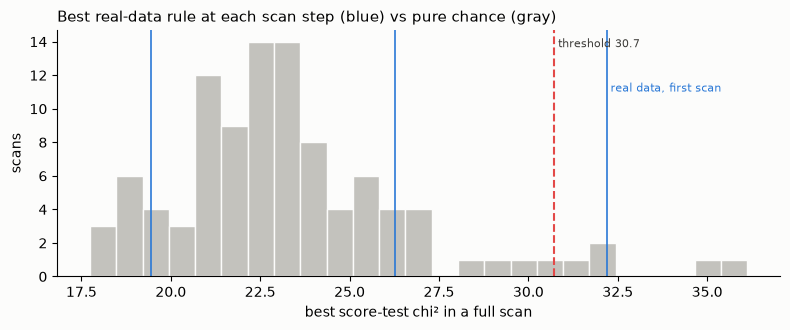

In [2]:
display(NULL.describe().T[['mean', 'std', '50%', 'max']].round(1).rename(columns={'50%': 'median'}))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(NULL['global'], bins=25, color='#c3c2bd', edgecolor='#fcfcfb')
ax.axvline(thr, color='#e34948', lw=1.5, ls='--')
ymax = ax.get_ylim()[1]
ax.text(thr, ymax * 0.93, f' threshold {thr:.1f}', color='#3d3c39', fontsize=8)
for i, s in enumerate(R['steps'] + R6['steps']):
    ax.axvline(s['max']['global'], color='#2a78d6', lw=1.2)
ax.text(R['steps'][0]['max']['global'], ymax * 0.75, ' real data, first scan', color='#2a78d6', fontsize=8)
ax.set_xlabel('best score-test chi² in a full scan'); ax.set_ylabel('scans')
for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
ax.set_title('Best real-data rule at each scan step (blue) vs pure chance (gray)', loc='left', fontsize=11)
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb'); fig.tight_layout()
fig.savefig('figures/16_rule_scan_null.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()

## 2. Scan from SPEC4: selected rules and runners-up

In [3]:
for s in R['steps']:
    print(f"--- step {s['iteration'] + 1}: best per family", {k: round(v, 1) for k, v in s['max'].items()})
    display(s['top'].head(10)[['chi2', 'direction', 'family', 'label']].style.format({'chi2': '{:.1f}'}).hide(axis='index'))

--- step 1: best per family {'band': 32.2, 'subset': 32.2, 'pair': 19.8, 'global': 32.2}


chi2,direction,family,label
32.2,-,subset,"PRIOR_CARRIER_GRP in ['Carrier_3', 'Carrier_8', 'Missing'] @2016"
32.2,-,band,1 <= R_CARRIER_3_8_MISS_2016 <= 1
32.2,-,band,1 <= R_CARRIER_3_8_MISS_2016 <= 1 @early
32.2,-,band,R_CARRIER_3_8_MISS_2016 >= 1 @early
32.2,-,band,1 <= R_CARRIER_3_8_MISS_2016 <= 1 @2016
32.2,-,band,R_CARRIER_3_8_MISS_2016 >= 1 @2016
32.2,-,band,R_CARRIER_3_8_MISS_2016 >= 1
31.7,-,subset,"PRIOR_CARRIER_GRP in ['Carrier_3', 'Carrier_8', 'Missing', 'Other'] @2016"
31.6,-,subset,"PRIOR_CARRIER_GRP in ['Carrier_3', 'Carrier_6', 'Carrier_8', 'Missing', 'Other'] @2016"
30.8,-,subset,"PRIOR_CARRIER_GRP in ['Carrier_3', 'Carrier_6', 'Carrier_8', 'Missing'] @2016"


--- step 2: best per family {'band': 23.6, 'subset': 26.3, 'pair': 19.2, 'global': 26.3}


chi2,direction,family,label
26.3,-,subset,"COV_PKG_TYPE in ['High', 'Missing'] @2016"
23.6,-,subset,COV_PKG_TYPE in ['High'] @2016
23.6,-,band,1 <= PKG_ORDINAL <= 1 @2016
23.6,-,band,PKG_ORDINAL >= 1 @2016
23.1,-,band,CAT_ZONE >= 4 @2016
23.1,-,band,4 <= CAT_ZONE <= 5 @2016
21.8,+,band,PKG_ORDINAL <= 0 @2016
21.8,+,subset,"COV_PKG_TYPE in ['Low', 'Medium'] @2016"
20.7,+,band,0.285714 <= VEH_SHARE[VEHICLE_AGE<6] <= 1 @early
20.7,+,band,VEH_SHARE[VEHICLE_AGE<6] >= 0.285714 @early


**Reading:** out of every band, level subset and pairwise rule (hundreds of thousands of candidates across 518 numeric and 17 categorical columns × 5 era scopes), exactly **one rule beats what pure chance produces** (χ² 32.2 vs threshold 30.7): previous carrier ∈ {Carrier_3, Carrier_8, Missing} in 2016 lowers conversion (log-odds −0.5). The runners-up after adding it are all 2016 package / CAT-zone variants (χ² ≤ 26.3), which point to an era-specific package effect rather than another step rule.

## 3. Existing terms with era-specific values (seed 0, vs SPEC5 = SPEC4 + the scan's rule)

In [4]:
def r_(sp, seeds=(0,)):
    return C.cv_score('fx', L, FM.columns(sp), 'formula', {'spec': sp, 'C': 0.1, 'intercepts': '2era'}, seeds=seeds, log=False)
b5 = r_(FS.SPEC5)
rows = {}
for x in FS.SPEC5:
    if x['col'].startswith('R_CARRIER'):
        continue
    rows[f"{x['col']} + 2016-only copy"] = cmp(r_(FS.SPEC5 + [dict(x, scope='2016')]), b5)
    if x['scope'] in ('all', 'split', 'early'):
        rows[f"{x['col']} per-era"] = cmp(r_([dict(z, scope='per-era') if z is x else z for z in FS.SPEC5]), b5)
te = pd.DataFrame(rows).T; te['z_ll'] = te['Δll(+better)'] / te['se_ll']
te.sort_values('Δll(+better)', ascending=False).style.format(fmt)

,auc,Δauc,se_auc,Δll(+better),se_ll,z_ll
PKG_ORDINAL per-era,0.72373,+0.00143,0.00028,+4.44,1.13,+3.9
PKG_ORDINAL + 2016-only copy,0.72367,+0.00137,0.00029,+4.15,1.17,+3.5
CAT_ZONE + 2016-only copy,0.72271,+0.00041,0.00017,+1.03,0.67,+1.5
VEH_LUXURY_SHARE + 2016-only copy,0.72267,+0.00037,0.00025,+0.71,0.57,+1.3
CAT_ZONE per-era,0.72256,+0.00026,0.00017,+0.58,0.61,+1.0
DISCOUNT_IND + 2016-only copy,0.72232,+0.00002,0.00003,+0.06,0.08,+0.8
DRV_AGE_35_50 per-era,0.72248,+0.00018,0.00005,+0.05,0.22,+0.2
ACS_POP_DENSITY + 2016-only copy,0.72228,-0.00002,0.00002,-0.01,0.06,-0.2
QUOTED_AMT + 2016-only copy,0.72229,-0.00001,0.00001,-0.05,0.05,-1.1
R_DPV_GT1 + 2016-only copy,0.72230,+0.00000,0.00003,-0.06,0.05,-1.2


**Reading:** the only existing term that clearly changes between eras is the **package ordinal** (+0.0014 ± 0.0003 per era; the 2016-only copy captures nearly all of it). All other per-era / 2016 copies are within noise and are not adopted.

## 4. Rescan from SPEC6 (same threshold)

In [5]:
for s in R6['steps']:
    print(f"--- step {s['iteration'] + 1}: best per family", {k: round(v, 1) for k, v in s['max'].items()})
    display(s['top'].head(10)[['chi2', 'direction', 'family', 'label']].style.format({'chi2': '{:.1f}'}).hide(axis='index'))
FINAL = R6.get('spec', FS.SPEC6)
print('final spec = SPEC6' + (f' + {len(R6["rules"])} more rules' if R6['rules'] else ' (no further rule passes)'))

--- step 1: best per family {'band': 18.9, 'subset': 13.9, 'pair': 19.4, 'global': 19.4}


chi2,direction,family,label
19.4,-,pair,[DRIVERS_PER_VEH >= 0.5] & [DRV_AGE_MEAN >= 18.0]
19.4,-,pair,[DRIVERS_PER_VEH >= 0.5] & [DRV_AGE_MAX >= 18.0]
18.9,+,band,VEH_SHARE[VEHICLE_AGE<6] >= 0.285714 @early
18.9,+,band,0.285714 <= VEH_SHARE[VEHICLE_AGE<6] <= 1 @early
18.6,+,band,0.333333 <= VEH_SHARE[VEHICLE_AGE<6] <= 1 @early
18.6,+,band,VEH_SHARE[VEHICLE_AGE<6] >= 0.333333 @early
18.5,+,pair,[DRIVERS_PER_VEH >= 1.0] & [QUOTE_CHANNEL = agent] @early
18.1,-,band,DRV_N[DRIVER_AGE<43] <= 4 @late
17.9,+,band,72 <= DRV_FIRST[SAFETY_RATING] <= 72 @2016
17.9,-,pair,[DRIVERS_PER_VEH < 1.0] & [QUOTED_AMT >= 7206.334999999999] @early


final spec = SPEC6 (no further rule passes)


**Reading:** from SPEC6 the best candidate has χ² 19.4, below the **average** pure-chance maximum (23.4). The scan is exhausted: no remaining band, subset or pairwise step rule on these columns is detectable with 29.5k quotes.

## 5. Confirmation: 15-fold CV and split-half replication
The new terms were chosen using all labeled quotes, so CV is not fully independent of the selection; the pure-chance threshold (rules) and the 5-se margin (package per era) are the guards. Each new term's coefficient is also fitted separately on two random halves.

In [6]:
PC = json.load(open('params_cats.json'))
cb15 = C.cv_score('cats15___copies__ohm_10', FE.add_cats(FE.add_static(lab)), PC['features'], 'cb', PC['params'])
r4 = r_(FS.SPEC4, (0, 1, 2))
specs = {'SPEC4 (29 params)': FS.SPEC4, 'SPEC5: + 2016 carrier rule': FS.SPEC5, 'SPEC6: + package per era': FS.SPEC6}
if R6['rules']:
    specs['final: + rescan rules'] = FINAL
RES, rows = {}, {}
for n, sp in specs.items():
    RES[n] = r = r_(sp, (0, 1, 2)); d4, dc = r['fold_aucs'] - r4['fold_aucs'], r['fold_aucs'] - cb15['fold_aucs']
    rows[n] = {'params': FM.Formula(sp, 1, '2era').fit(L.iloc[:6000], y[:6000]).n_params, 'AUC (15)': r['auc_mean'], 'top-decile': r['top_decile_prec'],
               'Δ vs SPEC4, seeds 1-2': d4[5:].mean(), 'se (1-2)': d4[5:].std() / np.sqrt(10), 'Δ vs CatBoost, seeds 1-2': dc[5:].mean()}
display(pd.DataFrame(rows).T.style.format({'params': '{:.0f}', 'AUC (15)': '{:.4f}', 'top-decile': '{:.1%}', 'Δ vs SPEC4, seeds 1-2': '{:+.4f}',
                                           'se (1-2)': '{:.4f}', 'Δ vs CatBoost, seeds 1-2': '{:+.4f}'}))
rng = np.random.default_rng(0); half = rng.random(len(y)) < 0.5
full = FM.Formula(FINAL, 0.1, '2era').fit(L, y)
fa, fb = (FM.Formula(FINAL, 0.1, '2era').fit(L[m], y[m]) for m in (half, ~half))
new = [n for n in full.names if n.startswith(('R_CARRIER', 'PKG_ORDINAL', 'RULE_'))]
pd.DataFrame({'coef (all)': full.coef_table().loc[new, 'coef'], 'coef (half A)': fa.coef_table().loc[new, 'coef'],
              'coef (half B)': fb.coef_table().loc[new, 'coef']}).style.format('{:+.3f}')

,params,AUC (15),top-decile,"Δ vs SPEC4, seeds 1-2",se (1-2),"Δ vs CatBoost, seeds 1-2"
SPEC4 (29 params),29,0.7206,31.1%,+0.0000,0.0000,+0.0062
SPEC5: + 2016 carrier rule,30,0.7222,31.6%,+0.0016,0.0004,+0.0078
SPEC6: + package per era,32,0.7236,31.8%,+0.0030,0.0006,+0.0092


,coef (all),coef (half A),coef (half B)
term,,,
PKG_ORDINAL:linear @2015,+0.021,-0.026,+0.060
PKG_ORDINAL:linear @2016,-0.320,-0.365,-0.273
PKG_ORDINAL:linear @2017-18,-0.077,-0.017,-0.136
R_CARRIER_3_8_MISS_2016:flag,-0.495,-0.492,-0.471


**Reading:** both additions hold up. SPEC6 is +0.0030 ± 0.0006 over SPEC4 on seeds 1-2 and +0.0092 over CatBoost, and the coefficients replicate in independent halves of the data (carrier rule −0.49 / −0.47; 2016 package −0.37 / −0.27).

## 6. Simulation test with the final formula
Same design as `15`: if the final formula were the true generator, how large would the CatBoost gap, blend gain and residual gain be? Real data inside the simulation range means nothing detectable is missing.

In [7]:
LC = FE.add_cats(FE.add_static(lab)); FX = PC['features']; cats = [c for c in FX if not pd.api.types.is_numeric_dtype(LC[c])]
FOLDS0 = [f for f in C.folds(lab) if f[0] == 0]
RP = PC['params'] | {'learning_rate': 0.02}
p_star = full.predict(L)
def pipeline(yy, tag):
    Lf, Lc = L.assign(CONVERT_IND=yy), LC.assign(CONVERT_IND=yy)
    fx = C.cv_score(f'{tag}_fx', Lf, FM.columns(FINAL), 'formula', {'spec': FINAL, 'C': 0.1, 'intercepts': '2era'}, seeds=(0,), log=False)
    cb = C.cv_score(f'{tag}_cb', Lc, FX, 'cb', PC['params'], seeds=(0,), log=False)
    Pf, Pc = fx['oof_all'][0], cb['oof_all'][0]
    out = {'formula': [], 'CatBoost': [], 'blend': []}; curves, base = [], []
    for s, k, tr, va in FOLDS0:
        m = FM.Formula(FINAL, 0.1, '2era').fit(Lf.iloc[tr], yy[tr]); btr, bva = m.decision(Lf.iloc[tr]), m.decision(Lf.iloc[va])
        Xva = C.cb_X(Lc.iloc[va][FX], cats)
        r = cbm.CatBoostClassifier(**RP, iterations=2000, early_stopping_rounds=200, use_best_model=False)
        r.fit(cbm.Pool(C.cb_X(Lc.iloc[tr][FX], cats), yy[tr], cat_features=cats, baseline=btr), eval_set=cbm.Pool(Xva, yy[va], cat_features=cats, baseline=bva))
        curves.append(np.array(r.get_evals_result()['validation']['AUC'])); base.append(roc_auc_score(yy[va], bva))
        out['formula'].append(roc_auc_score(yy[va], Pf[va])); out['CatBoost'].append(roc_auc_score(yy[va], Pc[va]))
        out['blend'].append(roc_auc_score(yy[va], 0.75 * Pf[va] + 0.25 * Pc[va]))
    Lm = max(map(len, curves)); bi = int(np.mean([np.pad(c, (0, Lm - len(c)), mode='edge') for c in curves], axis=0).argmax())
    res = {k: float(np.mean(v)) for k, v in out.items()}
    return res | {'formula − CatBoost': res['formula'] - res['CatBoost'], 'blend − formula': res['blend'] - res['formula'],
                  'residual CB − formula': float(np.mean([c[min(bi, len(c) - 1)] for c in curves]) - np.mean(base)), 'residual trees': bi + 1}
rows = {'real data': pipeline(y, 'final_real')}
rng = np.random.default_rng(2026)
for i in range(5):
    rows[f'simulation {i + 1}'] = pipeline((rng.random(len(y)) < p_star).astype(float), f'final_sim{i + 1}')
T = pd.DataFrame(rows).T; S = T.drop('real data')
T.loc['simulation mean'], T.loc['simulation sd'] = S.mean(), S.std()
for c in ['formula − CatBoost', 'blend − formula', 'residual CB − formula']:
    T.loc['z (real vs sims)', c] = (T.loc['real data', c] - T.loc['simulation mean', c]) / T.loc['simulation sd', c]
T.style.format('{:+.4f}', subset=['formula − CatBoost', 'blend − formula', 'residual CB − formula']).format('{:.4f}', subset=['formula', 'CatBoost', 'blend']).format('{:.0f}', subset=['residual trees'], na_rep='')

,formula,CatBoost,blend,formula − CatBoost,blend − formula,residual CB − formula,residual trees
real data,0.7237,0.7145,0.7240,+0.0092,+0.0002,+0.0003,150
simulation 1,0.7242,0.7118,0.7237,+0.0124,-0.0005,+0.0000,1
simulation 2,0.7286,0.7137,0.7278,+0.0149,-0.0008,+0.0000,3
simulation 3,0.7213,0.7086,0.7209,+0.0127,-0.0004,+0.0001,11
simulation 4,0.7238,0.7136,0.7237,+0.0101,-0.0001,+0.0001,3
simulation 5,0.7210,0.7089,0.7204,+0.0121,-0.0005,+0.0000,15
simulation mean,0.7238,0.7113,0.7233,+0.0124,-0.0004,+0.0000,7
simulation sd,0.0031,0.0025,0.0030,+0.0017,+0.0003,+0.0000,6
z (real vs sims),nan,nan,nan,-1.8906,+2.6596,+7.9248,


**Reading:** the gap to the simulations has mostly closed. Formula − CatBoost is +0.0092 vs +0.0124 ± 0.0017 if the formula were the truth (z −1.9, was −4 with SPEC4). CatBoost still adds a small, consistent amount on real data (blend +0.0002, residual +0.0003 at 150 trees, both 0 in simulation), so a little structure remains unexplained, but it is now worth ~0.0003 AUC.

## 7. Blend and submissions

In [8]:
FOLDS = C.folds(lab)
aucs = lambda P: np.array([roc_auc_score(y[va], P[s, va]) for s, k, tr, va in FOLDS])
rf = RES[list(RES)[-1]]
v4 = 0.75 * r4['oof_all'] + 0.25 * cb15['oof_all']
W = np.round(np.arange(0, 1.0001, 0.05), 2)
wf = float(W[int(np.argmax([aucs(w * rf['oof_all'] + (1 - w) * cb15['oof_all'])[:5].mean() for w in W]))])
cands = {'blend_v4 (previous best)': v4, 'final formula alone': rf['oof_all'], f'{wf:.2f} final formula + {1 - wf:.2f} CatBoost': wf * rf['oof_all'] + (1 - wf) * cb15['oof_all']}
base = aucs(v4); rows = {}
for n, P in cands.items():
    a = aucs(P); d = a - base
    rows[n] = {'AUC (15)': a.mean(), 'Δ vs blend_v4': d.mean(), 'se': d.std() / np.sqrt(15), 'Δ seeds 1-2': d[5:].mean(), 'se (1-2)': d[5:].std() / np.sqrt(10),
               'top-decile': np.mean([C.top_decile_precision(y, P[s]) for s in range(3)])}
tf = pd.DataFrame(rows).T
display(tf.style.format({'AUC (15)': '{:.4f}', 'Δ vs blend_v4': '{:+.4f}', 'se': '{:.4f}', 'Δ seeds 1-2': '{:+.4f}', 'se (1-2)': '{:.4f}', 'top-decile': '{:.1%}'}))
H = FM.prep(hold); hnum, hcat = RS.build_columns(H)
for r in R6['rules']:
    H[r['col']] = RS.materialize(r['rule'], hnum, hcat, H)
pf = full.predict(H)
out = {'formula_v3': C.write_submission('formula_v3', hold, pf)}
best_n = tf.index[-1]
if tf.loc[best_n, 'Δ seeds 1-2'] > 2 * tf.loc[best_n, 'se (1-2)']:
    cbp = pd.read_csv(sorted(glob.glob('../submissions/catboost_cats5_*.csv'))[-1]); assert (cbp.POLICY_ID.values == hold.POLICY_ID.values).all()
    p = wf * pf + (1 - wf) * cbp.CONVERT_IND_PRED.to_numpy()
    out['blend_v5'] = C.write_submission('blend_v5', hold, p)
print({k: v.name for k, v in out.items()}, f'| formula_v3: {pd.Series(pf).nunique()} distinct, mean {pf.mean():.4f}')
json.dump({'spec': FINAL, 'extra_rules': R6['rules'], 'C': 0.1, 'intercepts': '2era', 'cv_auc_15': rf['auc_mean'], 'blend_weight_formula': wf,
           'coefficients': full.coef_table()['coef'].round(6).to_dict(), 'submissions': {k: v.name for k, v in out.items()}},
          open('formula_v3_spec.json', 'w'), indent=1, default=str)
full.coef_table()[['coef']].style.format('{:+.6f}')

,AUC (15),Δ vs blend_v4,se,Δ seeds 1-2,se (1-2),top-decile
blend_v4 (previous best),0.7212,+0.0000,0.0000,+0.0000,0.0000,31.1%
final formula alone,0.7236,+0.0023,0.0002,+0.0023,0.0003,31.8%
0.85 final formula + 0.15 CatBoost,0.7239,+0.0027,0.0002,+0.0026,0.0003,31.6%


{'formula_v3': 'formula_v3_20261031.csv', 'blend_v5': 'blend_v5_20261031.csv'} | formula_v3: 7375 distinct, mean 0.1117


,coef
term,
era=2017-18,-1.648827
CREDIT_SCORE:step[650]>=650 @2015,+0.367010
QUOTED_AMT:linear @2015,-0.000054
QUOTED_AMT:linear @2016,-0.000061
QUOTED_AMT:linear @2017-18,-0.000019
ACS_POP_DENSITY:linear @2015,+0.000007
ACS_POP_DENSITY:linear @2016,+0.000012
ACS_POP_DENSITY:linear @2017-18,+0.000036
R_EDU_MAJ:flag @2017-18,+1.192989


## Conclusions
- **Final formula = `SPEC6` (32 parameters): 15-fold AUC 0.7236**, top-decile precision 31.8%. It adds to SPEC4 the 2016 carrier rule {Carrier_3, Carrier_8, Missing} and a package ordinal per era (strong only in 2016).
- The exhaustive scan with a pure-chance threshold found nothing further. Remaining structure is below the detection limit of this dataset.
- **`blend_v5` = 0.85 SPEC6 + 0.15 CatBoost (07): 15-fold AUC 0.7239**, +0.0026 ± 0.0003 over `blend_v4` on seeds 1-2 → **new best submission** (`submissions/blend_v5_20261031.csv`); `formula_v3_20261031.csv` is the formula alone (0.7236).